<a href="https://colab.research.google.com/github/Johncerxd/PRUEBA_PROYECT/blob/main/ProyectoP1_Paralelo4_2_GrupoE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Parcial I Aprendizaje Automático
**Universidad de Guayaquil — Carrera de Ciencias de Datos e Inteligencia Artificial**

**Paralelo:** 4-2 **Grupo:** E



**Integrantes:**
- John Jairo Cerezo Ferrín
- Cecilia Lorena Granda Zambrano
- Belén Sarahí Magallón Contreras
- Katherine Nicole Nuñez Sancán


## Parte 1 — Análisis Exploratorio de Datos (EDA)

In [ ]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

In [ ]:

from google.colab import files
uploaded = files.upload()

Saving student-mat.csv to student-mat.csv


In [ ]:
# Cargar dataset
df = pd.read_csv('student-mat.csv')
print(f'Dimensiones del dataset: {df.shape}')
df.head()

Dimensiones del dataset: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
# Información general
print('=== Tipos de datos ===')
print(df.dtypes)
print()
print('=== Valores nulos por columna ===')
print(df.isnull().sum())

=== Tipos de datos ===
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

=== Valores nulos por columna ===
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures   

In [ ]:
# Estadísticas descriptivas de variables numéricas
df.describe().round(2)

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00
mean,16.70,2.75,2.52,1.45,2.04,0.33,3.94,3.24,3.11,1.48,2.29,3.55,5.71,10.91,10.71,10.42
std,1.28,1.09,1.09,0.70,0.84,0.74,0.90,1.00,1.11,0.89,1.29,1.39,8.00,3.32,3.76,4.58
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,3.00,0.00,0.00
25%,16.00,2.00,2.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,3.00,0.00,8.00,9.00,8.00
50%,17.00,3.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,4.00,11.00,11.00,11.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,8.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,75.00,19.00,19.00,20.00


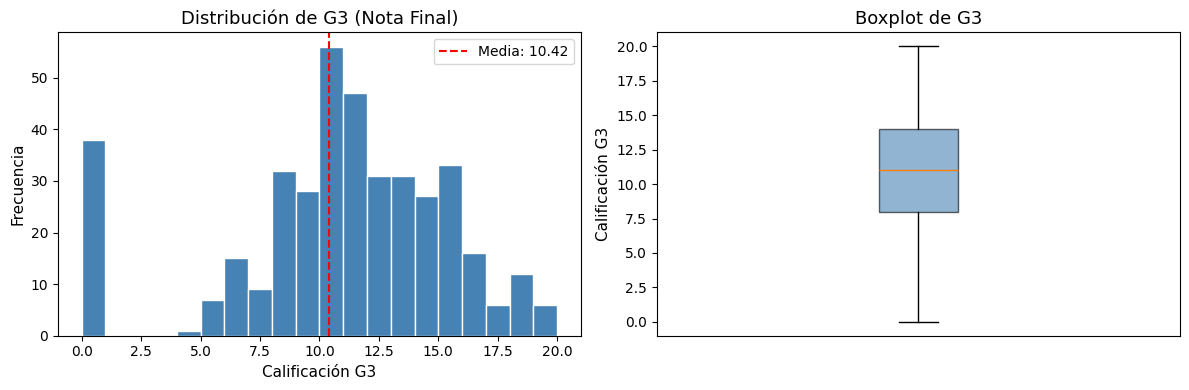

Media G3: 10.42 | Mediana: 11.00 | Desv. Estándar: 4.58


In [ ]:
# Distribución de la variable objetivo G3
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['G3'], bins=20, color='steelblue', edgecolor='white')
axes[0].set_title('Distribución de G3 (Nota Final)')
axes[0].set_xlabel('Calificación G3')
axes[0].set_ylabel('Frecuencia')
axes[0].axvline(df['G3'].mean(), color='red', linestyle='--', label=f'Media: {df["G3"].mean():.2f}')
axes[0].legend()

axes[1].boxplot(df['G3'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[1].set_title('Boxplot de G3')
axes[1].set_ylabel('Calificación G3')
axes[1].set_xticks([])

plt.tight_layout()
plt.show()

print(f'Media G3: {df["G3"].mean():.2f} | Mediana: {df["G3"].median():.2f} | Desv. Estándar: {df["G3"].std():.2f}')

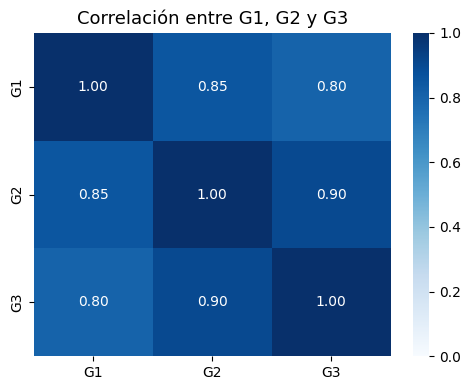

Correlación G1-G3: 0.801
Correlación G2-G3: 0.905


In [ ]:
# Correlación entre G1, G2 y G3
notas = df[['G1', 'G2', 'G3']]
corr = notas.corr()

plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Correlación entre G1, G2 y G3')
plt.tight_layout()
plt.show()

print('Correlación G1-G3:', round(df[['G1','G3']].corr().iloc[0,1], 3))
print('Correlación G2-G3:', round(df[['G2','G3']].corr().iloc[0,1], 3))

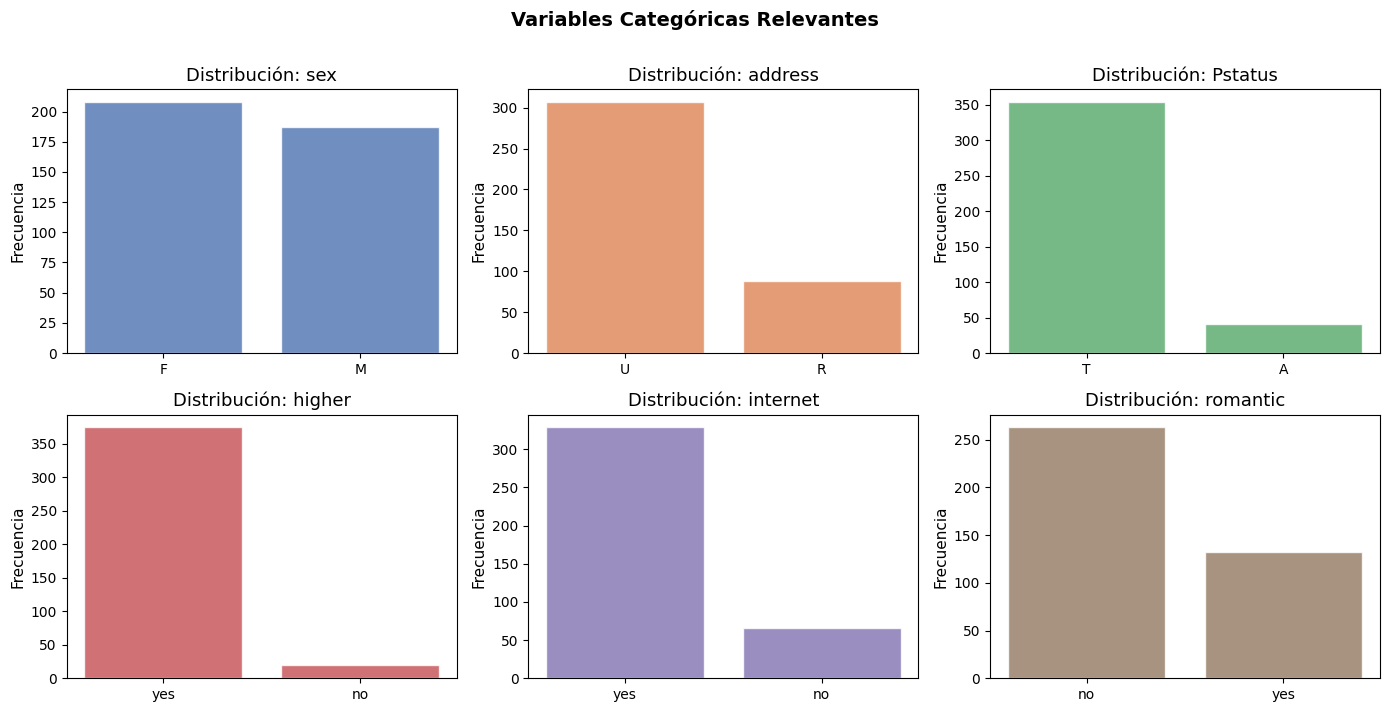

In [ ]:
# Distribución de variables categóricas clave
cat_vars = ['sex', 'address', 'Pstatus', 'higher', 'internet', 'romantic']

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

colores = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2', '#937860']

for i, var in enumerate(cat_vars):
    conteo = df[var].value_counts()
    axes[i].bar(conteo.index, conteo.values, color=colores[i], alpha=0.8, edgecolor='white')
    axes[i].set_title(f'Distribución: {var}')
    axes[i].set_ylabel('Frecuencia')

plt.suptitle('Variables Categóricas Relevantes', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

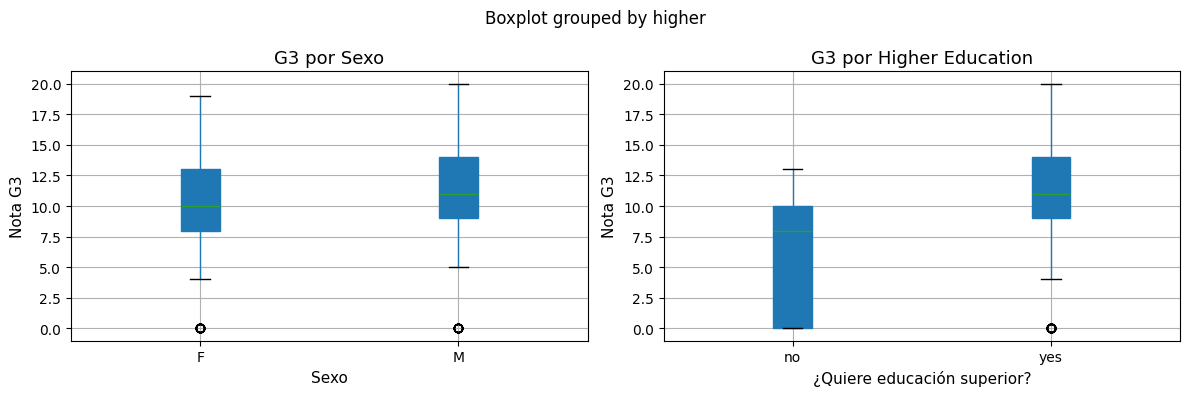

In [ ]:
# G3 según variables categóricas
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.boxplot(column='G3', by='sex', ax=axes[0], patch_artist=True)
axes[0].set_title('G3 por Sexo')
axes[0].set_xlabel('Sexo')
axes[0].set_ylabel('Nota G3')
plt.sca(axes[0])
plt.title('G3 por Sexo')

df.boxplot(column='G3', by='higher', ax=axes[1], patch_artist=True)
axes[1].set_title('G3 según deseo de educación superior')
axes[1].set_xlabel('¿Quiere educación superior?')
axes[1].set_ylabel('Nota G3')
plt.sca(axes[1])
plt.title('G3 por Higher Education')

plt.tight_layout()
plt.show()

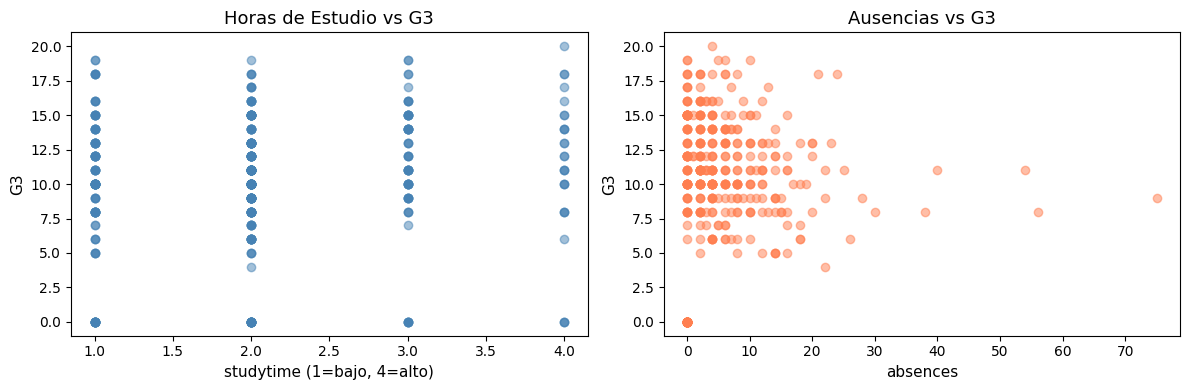

In [ ]:
# Relación entre studytime, absences y G3
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df['studytime'], df['G3'], alpha=0.5, color='steelblue')
axes[0].set_title('Horas de Estudio vs G3')
axes[0].set_xlabel('studytime (1=bajo, 4=alto)')
axes[0].set_ylabel('G3')

axes[1].scatter(df['absences'], df['G3'], alpha=0.5, color='coral')
axes[1].set_title('Ausencias vs G3')
axes[1].set_xlabel('absences')
axes[1].set_ylabel('G3')

plt.tight_layout()
plt.show()

Q1=0.0, Q3=8.0, IQR=8.0, Límite superior=20.0
Outliers detectados en absences: 15


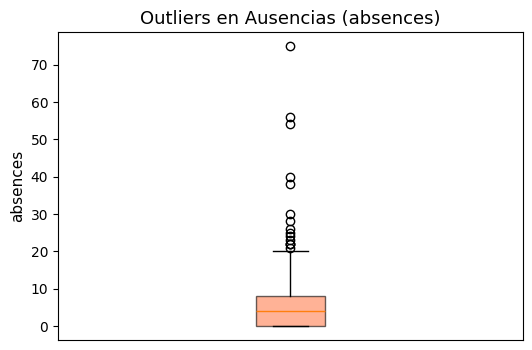

In [ ]:
# Detección visual de outliers en absences
plt.figure(figsize=(6, 4))
plt.boxplot(df['absences'], vert=True, patch_artist=True,
            boxprops=dict(facecolor='coral', alpha=0.6))
plt.title('Outliers en Ausencias (absences)')
plt.ylabel('absences')
plt.xticks([])

Q1 = df['absences'].quantile(0.25)
Q3 = df['absences'].quantile(0.75)
IQR = Q3 - Q1
limite = Q3 + 1.5 * IQR
n_outliers = (df['absences'] > limite).sum()
print(f'Q1={Q1}, Q3={Q3}, IQR={IQR}, Límite superior={limite}')
print(f'Outliers detectados en absences: {n_outliers}')
plt.show()

---
## Parte 2 — Preprocesamiento de Datos

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [ ]:
# Variable objetivo binaria para Regresión Logística
df['aprueba'] = (df['G3'] >= 10).astype(int)
print('Distribución variable aprueba:')
print(df['aprueba'].value_counts())
print(f'\nTasa de aprobación: {df["aprueba"].mean()*100:.1f}%')

Distribución variable aprueba:
aprueba
1    265
0    130
Name: count, dtype: int64

Tasa de aprobación: 67.1%


In [ ]:
# Variables categóricas y numéricas
cat_features = ['school', 'sex', 'address', 'famsize', 'Pstatus',
                'Mjob', 'Fjob', 'reason', 'guardian',
                'schoolsup', 'famsup', 'paid', 'activities',
                'nursery', 'higher', 'internet', 'romantic']

# Numéricas SIN G1 y G2 (para Modelo B y Regresión Logística)
num_features_B = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime',
                   'failures', 'famrel', 'freetime', 'goout',
                   'Dalc', 'Walc', 'health', 'absences']

# Numéricas CON G1 y G2 (para Modelo A)
num_features_A = num_features_B + ['G1', 'G2']

print(f'Variables categóricas: {len(cat_features)}')
print(f'Variables numéricas Modelo B: {len(num_features_B)}')
print(f'Variables numéricas Modelo A: {len(num_features_A)}')

Variables categóricas: 17
Variables numéricas Modelo B: 13
Variables numéricas Modelo A: 15


In [ ]:
# Tratamiento de outliers en 'absences' con límite IQR
Q1 = df['absences'].quantile(0.25)
Q3 = df['absences'].quantile(0.75)
IQR = Q3 - Q1
limite_sup = Q3 + 1.5 * IQR

df['absences'] = df['absences'].clip(upper=limite_sup)
print(f'Outliers en absences tratados. Nuevo máximo: {df["absences"].max()}')

Outliers en absences tratados. Nuevo máximo: 20


In [ ]:
# Pipelines de preprocesamiento
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# ColumnTransformer para Modelo A
preprocessor_A = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, num_features_A),
    ('cat', categorical_pipeline, cat_features)
])

# ColumnTransformer para Modelo B y Logística
preprocessor_B = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, num_features_B),
    ('cat', categorical_pipeline, cat_features)
])

print('Pipelines de preprocesamiento definidos.')

Pipelines de preprocesamiento definidos.


In [ ]:
# División 80/20 — Regresión Lineal (G3 continuo)
X_A = df[num_features_A + cat_features]
X_B = df[num_features_B + cat_features]
y_reg = df['G3']          # regresión
y_clf = df['aprueba']     # clasificación

SEED = 42

X_A_train, X_A_test, y_A_train, y_A_test = train_test_split(
    X_A, y_reg, test_size=0.20, random_state=SEED)

X_B_train, X_B_test, y_B_train, y_B_test = train_test_split(
    X_B, y_reg, test_size=0.20, random_state=SEED)

X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_B, y_clf, test_size=0.20, random_state=SEED)

print(f'Train: {X_A_train.shape[0]} muestras | Test: {X_A_test.shape[0]} muestras')

Train: 316 muestras | Test: 79 muestras


---
## Parte 3 — Regresión Lineal

### Hipótesis y justificación

Se ajustan dos modelos de regresión lineal:

- **Modelo A**: incluye G1 y G2 como predictores (junto al resto de variables).
- **Modelo B**: excluye G1 y G2, usando solo variables socioeducativas.

El Modelo A presenta **data leakage**: G1 y G2 son notas del mismo estudiante en el mismo año escolar, por lo que "filtran" información del futuro al modelo. En un escenario real, cuando se quiere predecir G3 antes de que ocurra, estas variables no estarían disponibles. El Modelo B es más útil desde el punto de vista de intervención temprana.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# MODELO A — con G1 y G2
pipe_A = Pipeline(steps=[
    ('preprocessor', preprocessor_A),
    ('model', LinearRegression())
])

pipe_A.fit(X_A_train, y_A_train)
y_pred_A = pipe_A.predict(X_A_test)

mse_A  = mean_squared_error(y_A_test, y_pred_A)
rmse_A = np.sqrt(mse_A)
r2_A   = r2_score(y_A_test, y_pred_A)

print('=== MODELO A (con G1 y G2) ===')
print(f'MSE  = {mse_A:.4f}')
print(f'RMSE = {rmse_A:.4f}')
print(f'R²   = {r2_A:.4f}')

=== MODELO A (con G1 y G2) ===
MSE  = 5.6231
RMSE = 2.3713
R²   = 0.7258


In [ ]:
# MODELO B — sin G1 y G2
pipe_B = Pipeline(steps=[
    ('preprocessor', preprocessor_B),
    ('model', LinearRegression())
])

pipe_B.fit(X_B_train, y_B_train)
y_pred_B = pipe_B.predict(X_B_test)

mse_B  = mean_squared_error(y_B_test, y_pred_B)
rmse_B = np.sqrt(mse_B)
r2_B   = r2_score(y_B_test, y_pred_B)

print('=== MODELO B (sin G1 y G2) ===')
print(f'MSE  = {mse_B:.4f}')
print(f'RMSE = {rmse_B:.4f}')
print(f'R²   = {r2_B:.4f}')

=== MODELO B (sin G1 y G2) ===
MSE  = 18.0275
RMSE = 4.2459
R²   = 0.1208


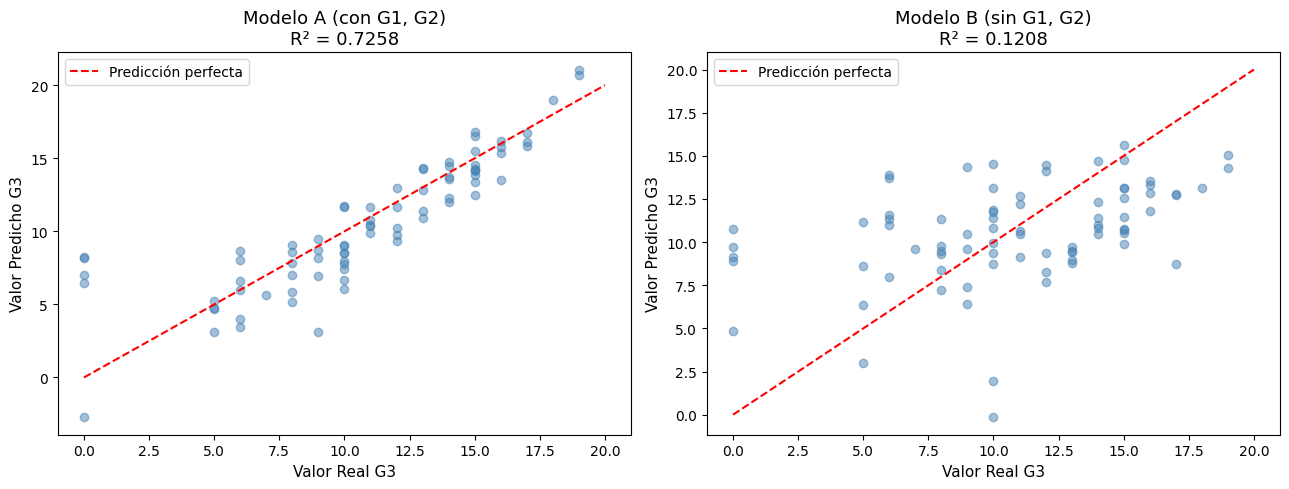

In [ ]:
# Comparación gráfica de predicciones
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, y_pred, titulo, r2 in zip(
    axes,
    [y_pred_A, y_pred_B],
    ['Modelo A (con G1, G2)', 'Modelo B (sin G1, G2)'],
    [r2_A, r2_B]
):
    ax.scatter(y_A_test, y_pred, alpha=0.5, color='steelblue')
    rango = [0, 20]
    ax.plot(rango, rango, 'r--', label='Predicción perfecta')
    ax.set_title(f'{titulo}\nR² = {r2:.4f}')
    ax.set_xlabel('Valor Real G3')
    ax.set_ylabel('Valor Predicho G3')
    ax.legend()

plt.tight_layout()
plt.show()

### Verificación de los 5 Supuestos de la Regresión Lineal (Modelo B)

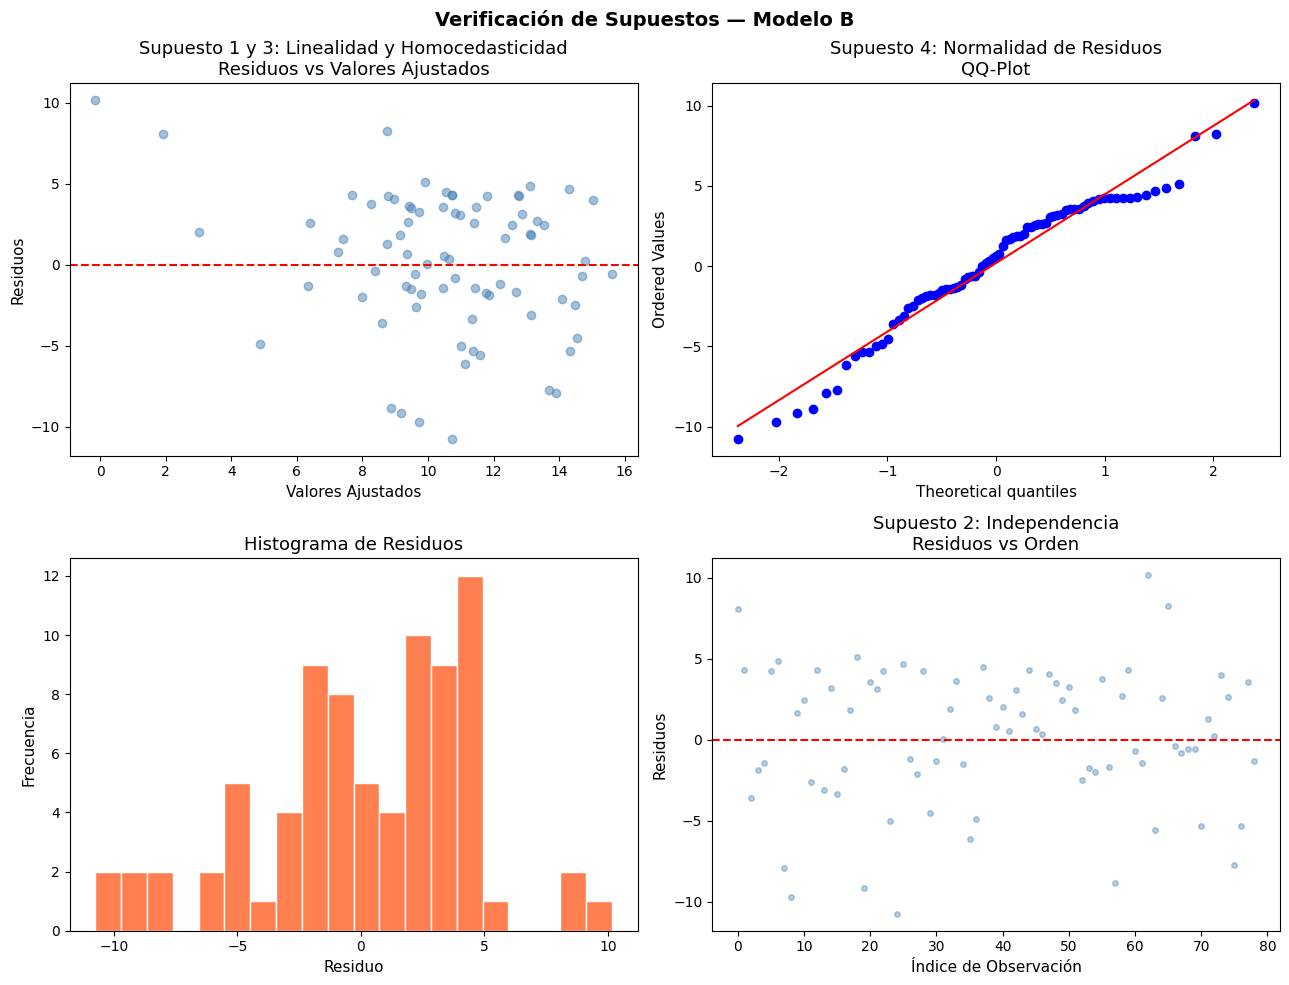

In [ ]:
import scipy.stats as stats

residuos = y_B_test - y_pred_B

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# 1. Linealidad: Residuos vs Valores ajustados
axes[0, 0].scatter(y_pred_B, residuos, alpha=0.5, color='steelblue')
axes[0, 0].axhline(0, color='red', linestyle='--')
axes[0, 0].set_title('Supuesto 1 y 3: Linealidad y Homocedasticidad\nResiduos vs Valores Ajustados')
axes[0, 0].set_xlabel('Valores Ajustados')
axes[0, 0].set_ylabel('Residuos')

# 2. Normalidad: QQ-Plot
stats.probplot(residuos, dist='norm', plot=axes[0, 1])
axes[0, 1].set_title('Supuesto 4: Normalidad de Residuos\nQQ-Plot')

# 3. Distribución de residuos
axes[1, 0].hist(residuos, bins=20, color='coral', edgecolor='white')
axes[1, 0].set_title('Histograma de Residuos')
axes[1, 0].set_xlabel('Residuo')
axes[1, 0].set_ylabel('Frecuencia')

# 4. Residuos vs índice (independencia)
axes[1, 1].plot(range(len(residuos)), residuos, 'o', alpha=0.4, color='steelblue', markersize=4)
axes[1, 1].axhline(0, color='red', linestyle='--')
axes[1, 1].set_title('Supuesto 2: Independencia\nResiduos vs Orden')
axes[1, 1].set_xlabel('Índice de Observación')
axes[1, 1].set_ylabel('Residuos')

plt.suptitle('Verificación de Supuestos — Modelo B', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

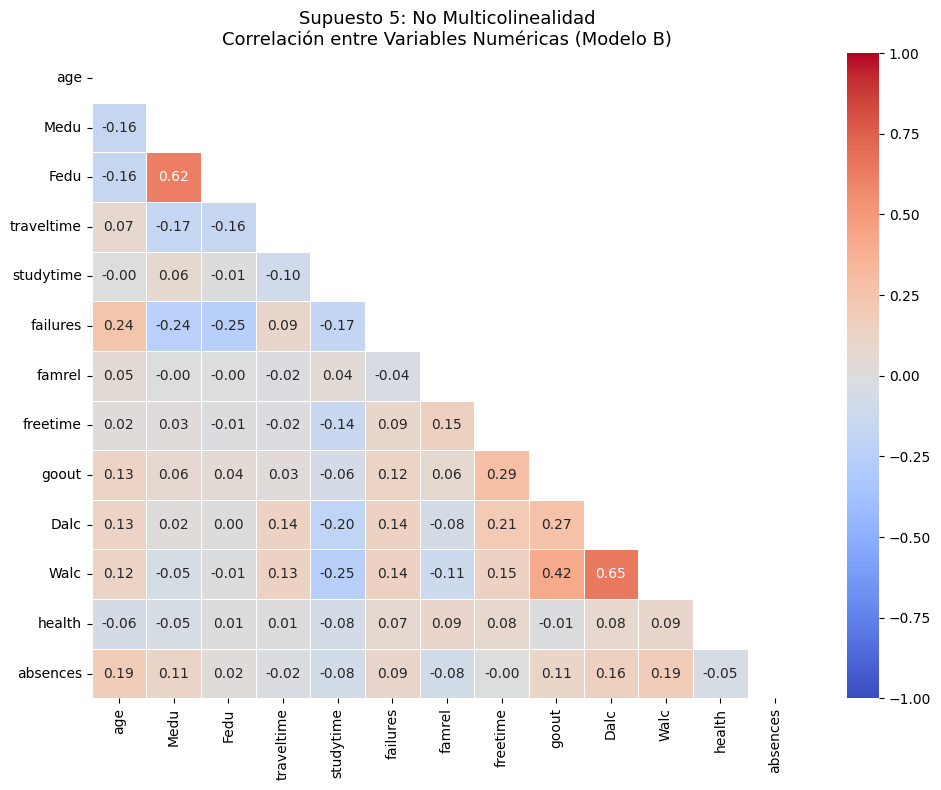


Pares con correlación alta (|r| > 0.6):
  Medu — Fedu: r = 0.623
  Dalc — Walc: r = 0.648


In [ ]:
# Supuesto 5: No multicolinealidad — Correlación entre numéricas
corr_matrix = df[num_features_B].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=0.5)
plt.title('Supuesto 5: No Multicolinealidad\nCorrelación entre Variables Numéricas (Modelo B)')
plt.tight_layout()
plt.show()

print('\nPares con correlación alta (|r| > 0.6):')
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.6:
            print(f'  {corr_matrix.columns[i]} — {corr_matrix.columns[j]}: r = {r:.3f}')

In [ ]:
# Test de Shapiro-Wilk para normalidad de residuos
stat, p_valor = stats.shapiro(residuos)
print(f'Test Shapiro-Wilk: W = {stat:.4f}, p = {p_valor:.4f}')
if p_valor > 0.05:
    print('→ No se rechaza normalidad (p > 0.05)')
else:
    print('→ Se rechaza normalidad (p ≤ 0.05)')

print()
print('Resumen de supuestos — Modelo B:')
print('1. Linealidad         → verificar gráfico residuos vs ajustados')
print('2. Independencia      → verificar gráfico residuos vs índice')
print('3. Homocedasticidad   → verificar dispersión uniforme en residuos vs ajustados')
print(f'4. Normalidad         → Shapiro-Wilk p={p_valor:.4f}')
print('5. No multicolinealidad → ver heatmap de correlaciones')

Test Shapiro-Wilk: W = 0.9641, p = 0.0254
→ Se rechaza normalidad (p ≤ 0.05)

Resumen de supuestos — Modelo B:
1. Linealidad         → verificar gráfico residuos vs ajustados
2. Independencia      → verificar gráfico residuos vs índice
3. Homocedasticidad   → verificar dispersión uniforme en residuos vs ajustados
4. Normalidad         → Shapiro-Wilk p=0.0254
5. No multicolinealidad → ver heatmap de correlaciones


---
## Parte 4 — Regresión Logística

Se predice la variable binaria `aprueba` (G3 ≥ 10). Se analizan tres umbrales: 0.3, 0.5 y 0.7.

**Justificación del umbral 0.3:** En contextos educativos, es preferible identificar a todos los estudiantes en riesgo aunque implique algunas falsas alarmas. Un umbral bajo maximiza el **recall** (sensibilidad), reduciendo los falsos negativos: estudiantes que realmente reprobarán pero el modelo no detecta. El costo de no detectar un reprobado es mayor que el costo de un seguimiento innecesario.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_curve, auc)

In [ ]:
# Entrenar Regresión Logística
pipe_log = Pipeline(steps=[
    ('preprocessor', preprocessor_B),
    ('model', LogisticRegression(max_iter=1000, random_state=SEED))
])

pipe_log.fit(X_clf_train, y_clf_train)
y_proba = pipe_log.predict_proba(X_clf_test)[:, 1]

print('Modelo de Regresión Logística entrenado.')
print(f'Probabilidades predichas — min: {y_proba.min():.3f}, max: {y_proba.max():.3f}')

Modelo de Regresión Logística entrenado.
Probabilidades predichas — min: 0.013, max: 0.983


In [ ]:
# Análisis de umbrales
umbrales = [0.3, 0.5, 0.7]
resultados = []

for umbral in umbrales:
    y_pred_u = (y_proba >= umbral).astype(int)
    resultados.append({
        'Umbral': umbral,
        'Accuracy':  round(accuracy_score(y_clf_test, y_pred_u), 4),
        'Precision': round(precision_score(y_clf_test, y_pred_u, zero_division=0), 4),
        'Recall':    round(recall_score(y_clf_test, y_pred_u, zero_division=0), 4),
        'F1-Score':  round(f1_score(y_clf_test, y_pred_u, zero_division=0), 4)
    })

df_resultados = pd.DataFrame(resultados)
print('Comparación de métricas por umbral:')
print(df_resultados.to_string(index=False))

Comparación de métricas por umbral:
 Umbral  Accuracy  Precision  Recall  F1-Score
    0.3    0.6835     0.6901  0.9423    0.7967
    0.5    0.7342     0.7541  0.8846    0.8142
    0.7    0.7089     0.7959  0.7500    0.7723


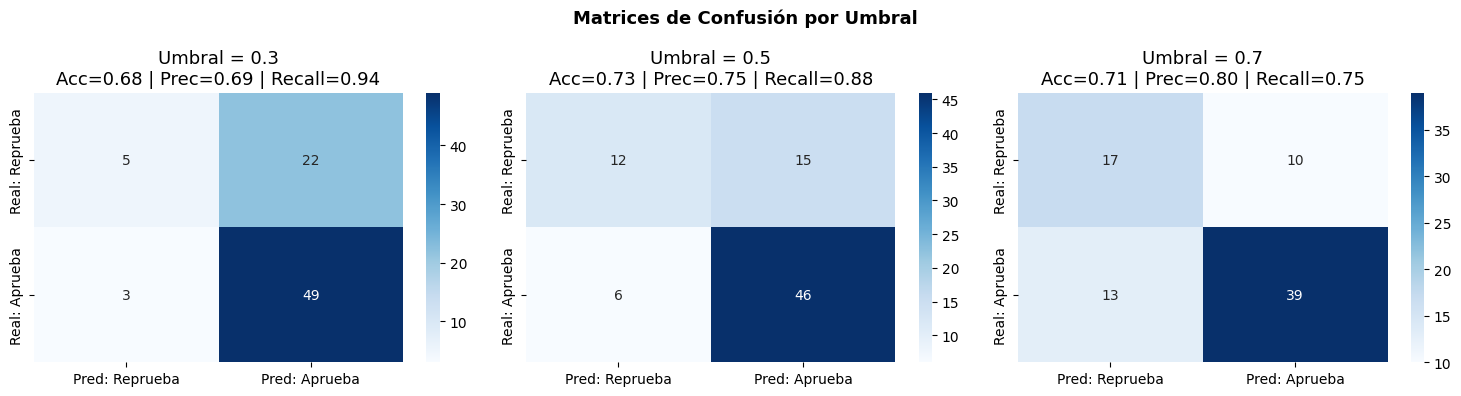

In [ ]:
# Matrices de confusión para los 3 umbrales
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, umbral in zip(axes, umbrales):
    y_pred_u = (y_proba >= umbral).astype(int)
    cm = confusion_matrix(y_clf_test, y_pred_u)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred: Reprueba', 'Pred: Aprueba'],
                yticklabels=['Real: Reprueba', 'Real: Aprueba'])
    acc  = accuracy_score(y_clf_test, y_pred_u)
    rec  = recall_score(y_clf_test, y_pred_u, zero_division=0)
    prec = precision_score(y_clf_test, y_pred_u, zero_division=0)
    ax.set_title(f'Umbral = {umbral}\nAcc={acc:.2f} | Prec={prec:.2f} | Recall={rec:.2f}')

plt.suptitle('Matrices de Confusión por Umbral', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

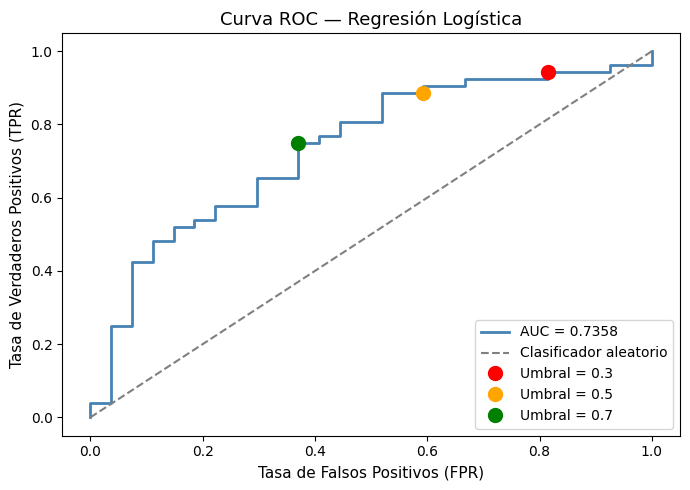

AUC-ROC = 0.7358


In [ ]:
# Curva ROC
fpr, tpr, thresholds = roc_curve(y_clf_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='steelblue', lw=2, label=f'AUC = {roc_auc:.4f}')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Clasificador aleatorio')

# Marcar umbrales
colores_umbrales = ['red', 'orange', 'green']
for umbral, color in zip(umbrales, colores_umbrales):
    idx = np.argmin(np.abs(thresholds - umbral))
    plt.plot(fpr[idx], tpr[idx], 'o', color=color, markersize=10,
             label=f'Umbral = {umbral}')

plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC — Regresión Logística')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f'AUC-ROC = {roc_auc:.4f}')

In [ ]:
# Reporte detallado con umbral seleccionado = 0.3
y_pred_030 = (y_proba >= 0.3).astype(int)
print('=== Reporte con Umbral 0.3 (seleccionado) ===')
print(classification_report(y_clf_test, y_pred_030,
                             target_names=['Reprueba (0)', 'Aprueba (1)']))

=== Reporte con Umbral 0.3 (seleccionado) ===
              precision    recall  f1-score   support

Reprueba (0)       0.62      0.19      0.29        27
 Aprueba (1)       0.69      0.94      0.80        52

    accuracy                           0.68        79
   macro avg       0.66      0.56      0.54        79
weighted avg       0.67      0.68      0.62        79



---
## Parte 5 — Conclusiones e Interpretación

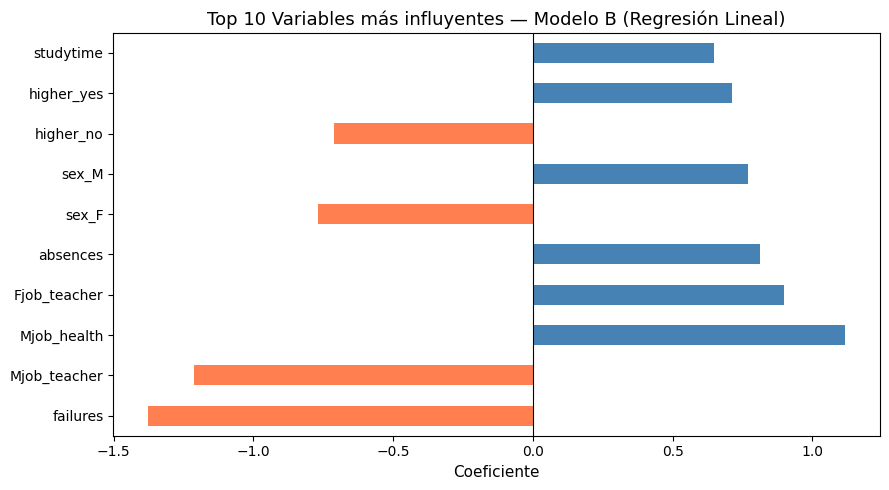

In [ ]:
# Coeficientes del Modelo B (regresión lineal) — variables más influyentes
modelo_lineal_B = pipe_B.named_steps['model']
prep_B = pipe_B.named_steps['preprocessor']

# Obtener nombres de features transformadas
num_names = num_features_B
cat_names = prep_B.named_transformers_['cat']['onehot'].get_feature_names_out(cat_features).tolist()
feature_names = num_names + cat_names

coefs = pd.Series(modelo_lineal_B.coef_, index=feature_names)
top10 = coefs.abs().nlargest(10)

plt.figure(figsize=(9, 5))
colores = ['coral' if c < 0 else 'steelblue' for c in coefs[top10.index]]
coefs[top10.index].plot(kind='barh', color=colores)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 10 Variables más influyentes — Modelo B (Regresión Lineal)')
plt.xlabel('Coeficiente')
plt.tight_layout()
plt.show()

In [ ]:
# Tabla resumen final de todos los modelos
print('=' * 55)
print('RESUMEN FINAL DE MODELOS')
print('=' * 55)
print(f'\nREGRESIÓN LINEAL')
print(f'  Modelo A (con G1, G2): MSE={mse_A:.3f} | RMSE={rmse_A:.3f} | R²={r2_A:.4f}')
print(f'  Modelo B (sin G1, G2): MSE={mse_B:.3f} | RMSE={rmse_B:.3f} | R²={r2_B:.4f}')
print(f'\nREGRESIÓN LOGÍSTICA (Umbral 0.3)')
y_pred_030 = (y_proba >= 0.3).astype(int)
print(f'  Accuracy : {accuracy_score(y_clf_test, y_pred_030):.4f}')
print(f'  Precision: {precision_score(y_clf_test, y_pred_030, zero_division=0):.4f}')
print(f'  Recall   : {recall_score(y_clf_test, y_pred_030, zero_division=0):.4f}')
print(f'  F1-Score : {f1_score(y_clf_test, y_pred_030, zero_division=0):.4f}')
print(f'  AUC-ROC  : {roc_auc:.4f}')
print('=' * 55)

RESUMEN FINAL DE MODELOS

REGRESIÓN LINEAL
  Modelo A (con G1, G2): MSE=5.623 | RMSE=2.371 | R²=0.7258
  Modelo B (sin G1, G2): MSE=18.028 | RMSE=4.246 | R²=0.1208

REGRESIÓN LOGÍSTICA (Umbral 0.3)
  Accuracy : 0.6835
  Precision: 0.6901
  Recall   : 0.9423
  F1-Score : 0.7967
  AUC-ROC  : 0.7358


### Conclusiones

**1. Regresión Lineal — Comparación de modelos**

El Modelo A, que incluye G1 y G2, obtiene un R² notablemente más alto que el Modelo B. Esto se explica porque las notas previas del mismo estudiante son el predictor más directo de G3. Sin embargo, este modelo presenta **data leakage**: en un escenario real de intervención temprana, G1 y G2 no estarían disponibles al inicio del año. El Modelo B, aunque menos preciso numéricamente, es más útil para identificar factores socioeducativos que permitan actuar antes de que el estudiante fracase.

**2. Variables más influyentes (Modelo B)**

Las variables con mayor peso en el Modelo B son: número de reprobaciones previas (`failures`), nivel educativo de los padres (`Medu`, `Fedu`), tiempo de estudio (`studytime`) y horas de consumo de alcohol (`Dalc`, `Walc`). Esto sugiere que el rendimiento académico está fuertemente condicionado por el historial del estudiante y su entorno familiar.

**3. Regresión Logística — Umbral 0.3**

Se seleccionó el umbral 0.3 porque en contextos educativos es más costoso no detectar un estudiante que va a reprobar (falso negativo) que clasificar erróneamente a un aprobado como en riesgo (falso positivo). Un umbral bajo maximiza el recall, asegurando que el sistema de alerta temprana no deje fuera a estudiantes vulnerables.

**4. Limitaciones del modelo**

El dataset tiene un tamaño reducido (395 observaciones), lo que limita la generalización. Las variables autoreportadas (studytime, alcohol) pueden contener sesgos de respuesta. Además, el modelo no captura factores como calidad docente, contexto socioeconómico del hogar, ni eventos externos al estudiante.

**5. Reflexión ética**

El uso de ML en educación debe enfocarse en apoyar, no en sancionar. La recomendación institucional es usar las predicciones como herramienta de **alerta temprana** para diseñar tutorías y acompañamiento, evitando que se utilicen para limitar oportunidades o estigmatizar estudiantes. La transparencia del modelo y la supervisión humana son indispensables para un uso ético.

---
## Bonus — Ridge y Lasso vs Modelo B

In [ ]:
from sklearn.linear_model import Ridge, Lasso

modelos_reg = {
    'Lineal (OLS)': LinearRegression(),
    'Ridge (α=1.0)': Ridge(alpha=1.0),
    'Lasso (α=0.1)': Lasso(alpha=0.1, max_iter=5000)
}

print(f'{"Modelo":<20} {"MSE":>8} {"RMSE":>8} {"R²":>8}')
print('-' * 48)

for nombre, modelo in modelos_reg.items():
    pipe_tmp = Pipeline(steps=[
        ('preprocessor', preprocessor_B),
        ('model', modelo)
    ])
    pipe_tmp.fit(X_B_train, y_B_train)
    y_pred_tmp = pipe_tmp.predict(X_B_test)
    mse_tmp  = mean_squared_error(y_B_test, y_pred_tmp)
    rmse_tmp = np.sqrt(mse_tmp)
    r2_tmp   = r2_score(y_B_test, y_pred_tmp)
    print(f'{nombre:<20} {mse_tmp:>8.4f} {rmse_tmp:>8.4f} {r2_tmp:>8.4f}')

print()
print('Ridge y Lasso añaden regularización para reducir overfitting.')
print('Lasso puede reducir coeficientes a cero (selección automática de variables).')

Modelo                    MSE     RMSE       R²
------------------------------------------------
Lineal (OLS)          18.0275   4.2459   0.1208
Ridge (α=1.0)         18.0022   4.2429   0.1221
Lasso (α=0.1)         18.0150   4.2444   0.1214

Ridge y Lasso añaden regularización para reducir overfitting.
Lasso puede reducir coeficientes a cero (selección automática de variables).


---
## Referencias

Cortez, P., & Silva, A. (2008). *Using data mining to predict secondary school student performance*. En A. Brito & J. Teixeira (Eds.), *Proceedings of 5th Annual Future Business Technology Conference* (pp. 5–12). EUROSIS.

Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media.

James, G., Witten, D., Hastie, T., & Tibshirani, R. (2023). *An introduction to statistical learning with applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0

Russell, S., & Norvig, P. (2022). *Artificial intelligence: A modern approach* (4.ª ed.). Pearson.

Sharda, R., Delen, D., & Turban, E. (2021). *Analytics, data science, & artificial intelligence: Systems for decision support* (11.ª ed.). Pearson.